<a href="https://colab.research.google.com/github/Oyakata32/Lesson-18/blob/main/Zaj%C4%99cia_18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Sprawdzenie wersji scikit-learn
import sklearn
print(f"Wersja scikit-learn: {sklearn.__version__}")
# Główne moduły scikit-learn
from sklearn import datasets # Wbudowane datasety
from sklearn import preprocessing # Skalowanie, kodowanie
from sklearn import model_selection # Train/test split, CV
from sklearn import metrics # Metryki ewaluacji
from sklearn import linear_model # Modele liniowe
from sklearn import tree # Drzewa decyzyjne
from sklearn import ensemble # Random Forest, Gradient Boosting
from sklearn import neighbors # k-NN
from sklearn import svm # Support Vector Machines
from sklearn import cluster # Klasteryzacja
# Przykład: wczytanie wbudowanego datasetu
iris = datasets.load_iris()
print(f"\nDataset Iris:")
print(f" Cechy: {iris.feature_names}")
print(f" Klasy: {iris.target_names}")
print(f" Rozmiar X: {iris.data.shape}")
print(f" Rozmiar y: {iris.target.shape}")
# Konwersja do DataFrame dla wygody
import pandas as pd
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['target'] = iris.target
df['species'] = df['target'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})
print(f"\nPierwsze 5 wierszy:")
print(df.head())

Wersja scikit-learn: 1.6.1

Dataset Iris:
 Cechy: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
 Klasy: ['setosa' 'versicolor' 'virginica']
 Rozmiar X: (150, 4)
 Rozmiar y: (150,)

Pierwsze 5 wierszy:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target species  
0       0  setosa  
1       0  setosa  
2       0  setosa  
3       0  setosa  
4       0  setosa  


In [ ]:
# Scikit-learn ma spójny interfejs dla WSZYSTKICH algorytmów:
# 1. fit(X, y) - uczenie modelu na danych
# 2. predict(X) - predykcja dla nowych danych
# 3. score(X, y) - ewaluacja modelu
# 4. transform(X) - transformacja danych (dla preprocessorów)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
# Wczytanie danych
iris = load_iris()
X, y = iris.data, iris.target
# Podział na zbiór treningowy i testowy
X_train, X_test, y_train, y_test = train_test_split(
X, y,
test_size=0.3, # 30% na test
random_state=42, # dla reprodukowalności
stratify=y # zachowanie proporcji klas
)
print(f"Rozmiar zbioru treningowego: {X_train.shape[0]}")
print(f"Rozmiar zbioru testowego: {X_test.shape[0]}")
# Porównanie różnych algorytmów - TEN SAM interfejs!
models = {
  'Logistic Regression': LogisticRegression(max_iter=200),
  'Decision Tree': DecisionTreeClassifier(random_state=42),
  'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
  'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}
print("\nPorównanie algorytmów:")
print("-" * 50)
for name, model in models.items():
  # TEN SAM kod dla każdego modelu!
  model.fit(X_train, y_train) # Trening
  train_score = model.score(X_train, y_train) # Accuracy na train
  test_score = model.score(X_test, y_test) # Accuracy na test
  print(f"{name:25s} | Train: {train_score:.3f} | Test: {test_score:.3f}")



Rozmiar zbioru treningowego: 105
Rozmiar zbioru testowego: 45

Porównanie algorytmów:
--------------------------------------------------
Logistic Regression       | Train: 0.971 | Test: 0.933
Decision Tree             | Train: 1.000 | Test: 0.933
K-Nearest Neighbors       | Train: 0.971 | Test: 0.978
Random Forest             | Train: 1.000 | Test: 0.889


KLASYFIKACJA WIELOKLASOWA - Rozpoznawanie cyfr

Rozmiar danych: (1797, 64)
Liczba klas: 10 (cyfry 0-9)
Rozmiar obrazka: 8x8 = 64 piksele (cechy)


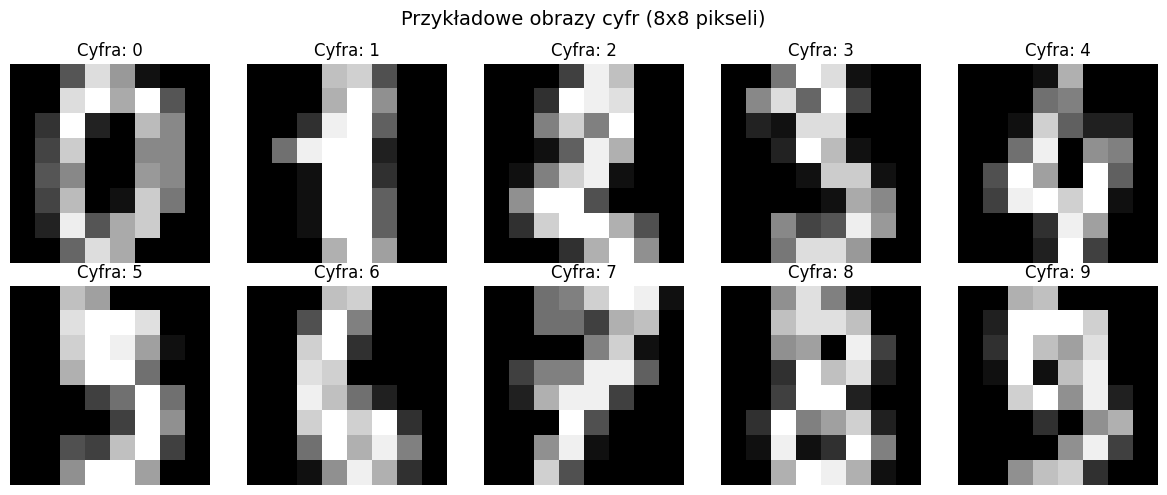


Accuracy: 0.9722

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.89      0.89      0.89        36
           2       1.00      1.00      1.00        35
           3       0.97      1.00      0.99        37
           4       0.97      1.00      0.99        36
           5       1.00      1.00      1.00        37
           6       1.00      0.97      0.99        36
           7       1.00      1.00      1.00        36
           8       0.89      0.89      0.89        35
           9       1.00      0.97      0.99        36

    accuracy                           0.97       360
   macro avg       0.97      0.97      0.97       360
weighted avg       0.97      0.97      0.97       360



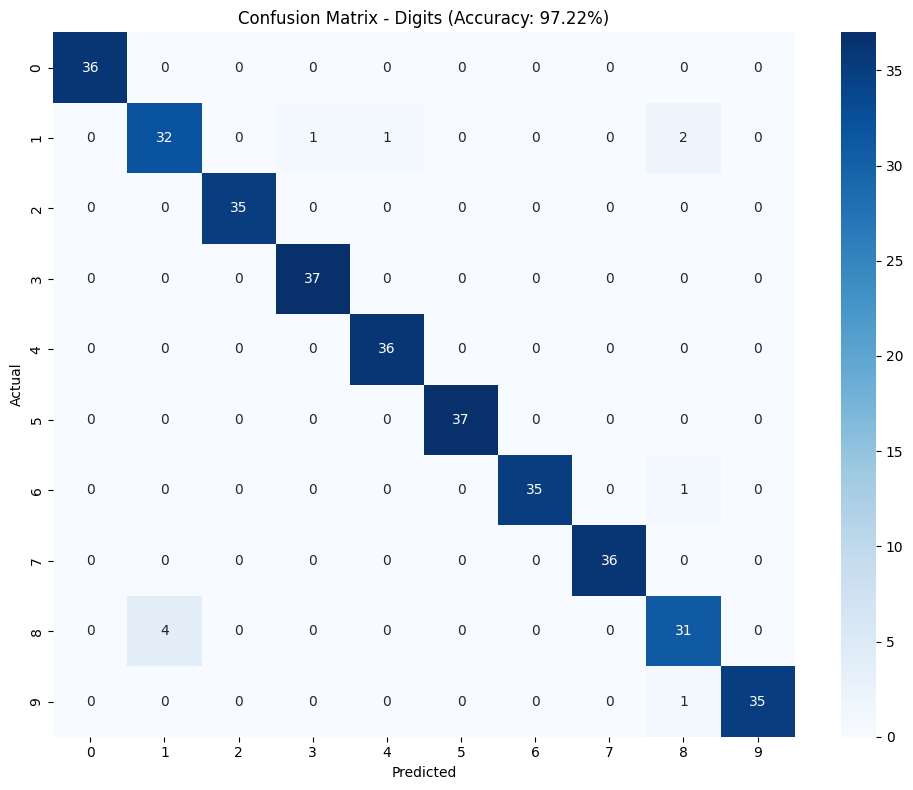


Liczba błędów: 10 z 360


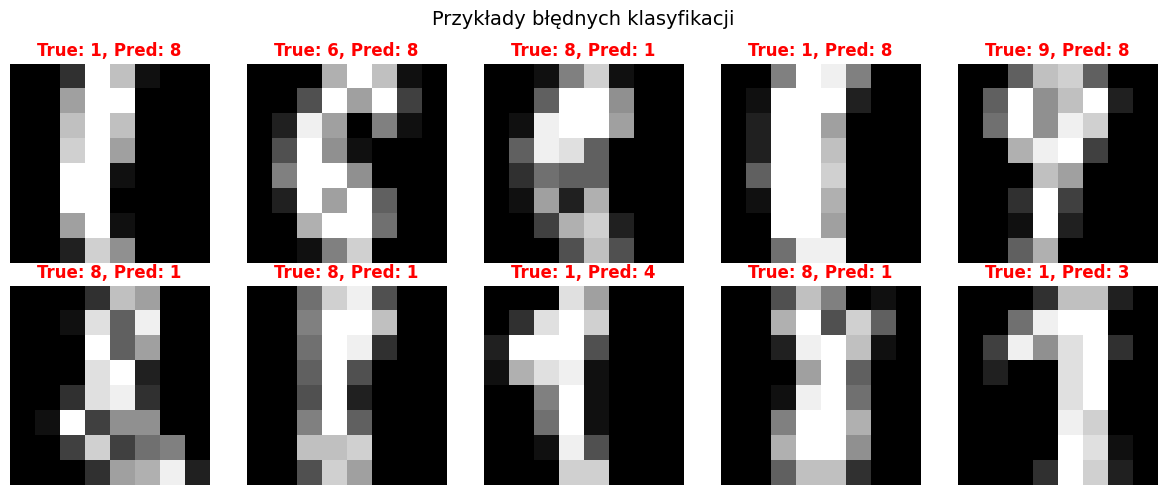

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
# Wczytanie datasetu MNIST (mała wersja - 8x8 pikseli)
digits = load_digits()
X, y = digits.data, digits.target
print("="*60)
print("KLASYFIKACJA WIELOKLASOWA - Rozpoznawanie cyfr")
print("="*60)
print(f"\nRozmiar danych: {X.shape}")
print(f"Liczba klas: {len(np.unique(y))} (cyfry 0-9)")
print(f"Rozmiar obrazka: 8x8 = 64 piksele (cechy)")
# Wizualizacja przykładowych cyfr
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
  ax.imshow(digits.images[i], cmap='gray')
  ax.set_title(f'Cyfra: {digits.target[i]}')
  ax.axis('off')
plt.suptitle('Przykładowe obrazy cyfr (8x8 pikseli)', fontsize=14)
plt.tight_layout()
plt.show()
# Podział i preprocessing
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
# Trening modelu
model = LogisticRegression(max_iter=5000, random_state=42)
model.fit(X_train_scaled, y_train)
# Predykcja
y_pred = model.predict(X_test_scaled)
accuracy = (y_pred == y_test).mean()
print(f"\nAccuracy: {accuracy:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred))
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
xticklabels=range(10), yticklabels=range(10))
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title(f'Confusion Matrix - Digits (Accuracy: {accuracy:.2%})')
plt.tight_layout()
plt.show()
# Przykłady błędnych predykcji
errors_idx = np.where(y_pred != y_test)[0]
print(f"\nLiczba błędów: {len(errors_idx)} z {len(y_test)}")
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
  if i < len(errors_idx):
    idx = errors_idx[i]
    img = X_test[idx].reshape(8, 8)
    ax.imshow(img, cmap='gray')
    ax.set_title(f'True: {y_test[idx]}, Pred: {y_pred[idx]}',
    color='red', fontweight='bold')
  ax.axis('off')
plt.suptitle('Przykłady błędnych klasyfikacji', fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
#Zadanie 1
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=20)
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Liczba obserwacji treningowych: {len(X_train)}")
print(f"Liczba obserwacji testowych: {len(X_test)}")
print(f"Accuracy na zbiorze testowym: {accuracy:.3f}")


Liczba obserwacji treningowych: 120
Liczba obserwacji testowych: 30
Accuracy na zbiorze testowym: 0.933


In [ ]:
#zadanie 2
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Wczytanie danych
wine = load_wine()
X, y = wine.data, wine.target

# Podział danych na treningowe i testowe
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Rozmiar zbioru treningowego: {X_train.shape[0]}")
print(f"Rozmiar zbioru testowego: {X_test.shape[0]}")

# Porównanie modeli
models = {
    'Logistic Regression': make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=200)
    ),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'K-Nearest Neighbors': make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=7)
    )
}

print("\nPorównanie algorytmów:")
print("-" * 60)

for name, model in models.items():
    model.fit(X_train, y_train)

    train_score = model.score(X_train, y_train)
    test_score = model.score(X_test, y_test)

    print(
        f"{name:25s} | "
        f"Train: {train_score:.3f} | "
        f"Test: {test_score:.3f}"
    )


Rozmiar zbioru treningowego: 142
Rozmiar zbioru testowego: 36

Porównanie algorytmów:
------------------------------------------------------------
Logistic Regression       | Train: 1.000 | Test: 0.972
Decision Tree             | Train: 1.000 | Test: 0.944
K-Nearest Neighbors       | Train: 0.965 | Test: 1.000


Rozmiar zbioru treningowego: 455
Rozmiar zbioru testowego: 114

Metryki na zbiorze testowym:
Accuracy:  0.956
Precision: 0.951
Recall:    0.929
F1-score:  0.940

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

Confusion Matrix:
TN = 70 | FP = 2
FN = 3 | TP = 39


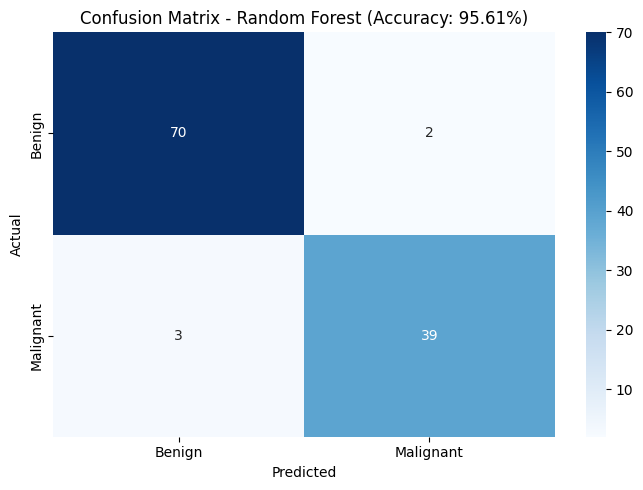

In [ ]:
#zadanie 3
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

breast = load_breast_cancer()
X, y = breast.data, breast.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Rozmiar zbioru treningowego: {X_train.shape[0]}")
print(f"Rozmiar zbioru testowego: {X_test.shape[0]}")

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, pos_label=0)
recall = recall_score(y_test, y_pred, pos_label=0)
f1 = f1_score(y_test, y_pred, pos_label=0)

print("\nMetryki na zbiorze testowym:")
print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=breast.target_names
))

cm = confusion_matrix(y_test, y_pred, labels=[1, 0])

print("Confusion Matrix:")
print(f"TN = {cm[0, 0]} | FP = {cm[0, 1]}")
print(f"FN = {cm[1, 0]} | TP = {cm[1, 1]}")

fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"],
    ax=ax
)

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Confusion Matrix - Random Forest (Accuracy: {accuracy:.2%})")

plt.tight_layout()
plt.show()


Rozmiar X: (20640, 8)
Rozmiar y: (20640,)

Wyniki na zbiorze testowym:
RMSE: 0.7456
R²:   0.5758


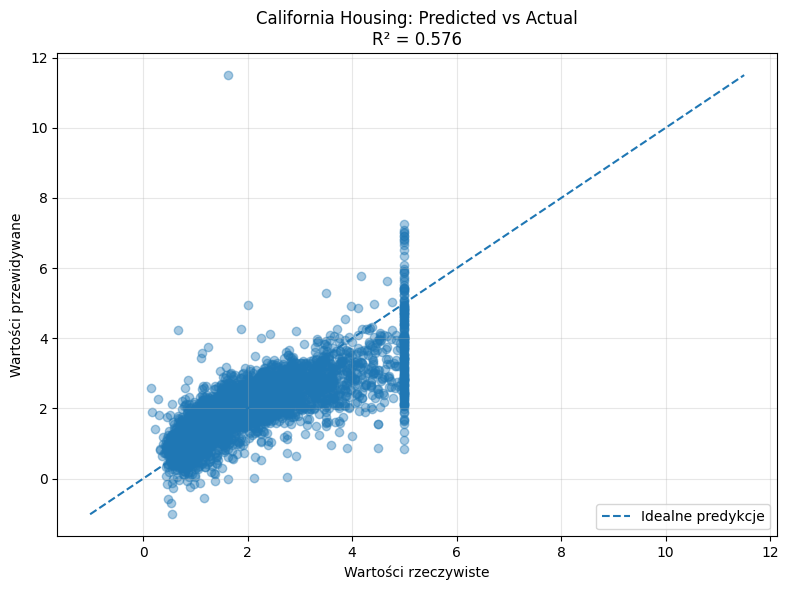

In [ ]:
#Zadanie 4
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline

housing = fetch_california_housing()
X, y = housing.data, housing.target

print("Rozmiar X:", X.shape)
print("Rozmiar y:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nWyniki na zbiorze testowym:")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4
)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    label="Idealne predykcje"
)

plt.xlabel("Wartości rzeczywiste")
plt.ylabel("Wartości przewidywane")
plt.title(f"California Housing: Predicted vs Actual\nR² = {r2:.3f}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


KLASTERYZACJA - Segmentacja klientów

Rozmiar danych: (300, 2)

Statystyki:
          Recency    Monetary
count  300.000000  300.000000
mean    -1.571847    1.369889
std      4.966799    6.651613
min     -8.856943   -8.721647
25%     -6.369915   -6.425157
50%     -2.544467    1.990289
75%      3.586992    8.295815
max      8.111867   11.734455


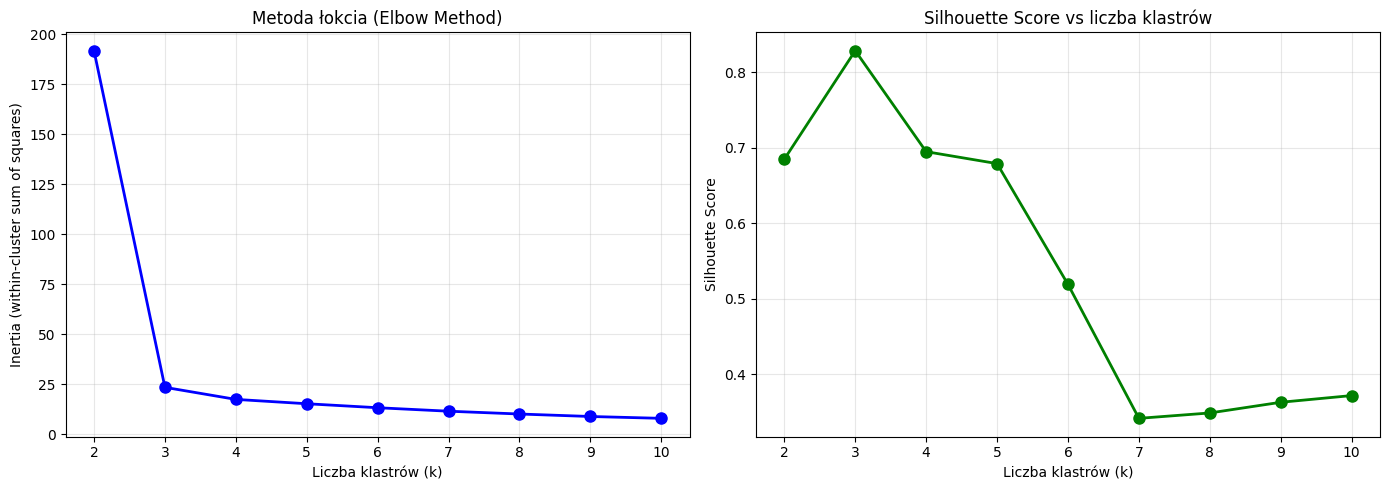


Optymalna liczba klastrów: 3
Silhouette Score: 0.829

Statystyki per klaster:
        Recency             Monetary      
           mean   std count     mean   std
Cluster                                   
0         -2.63  0.87   100     9.04  1.00
1         -6.88  0.82   100    -6.96  0.80
2          4.80  1.56   100     2.03  1.39


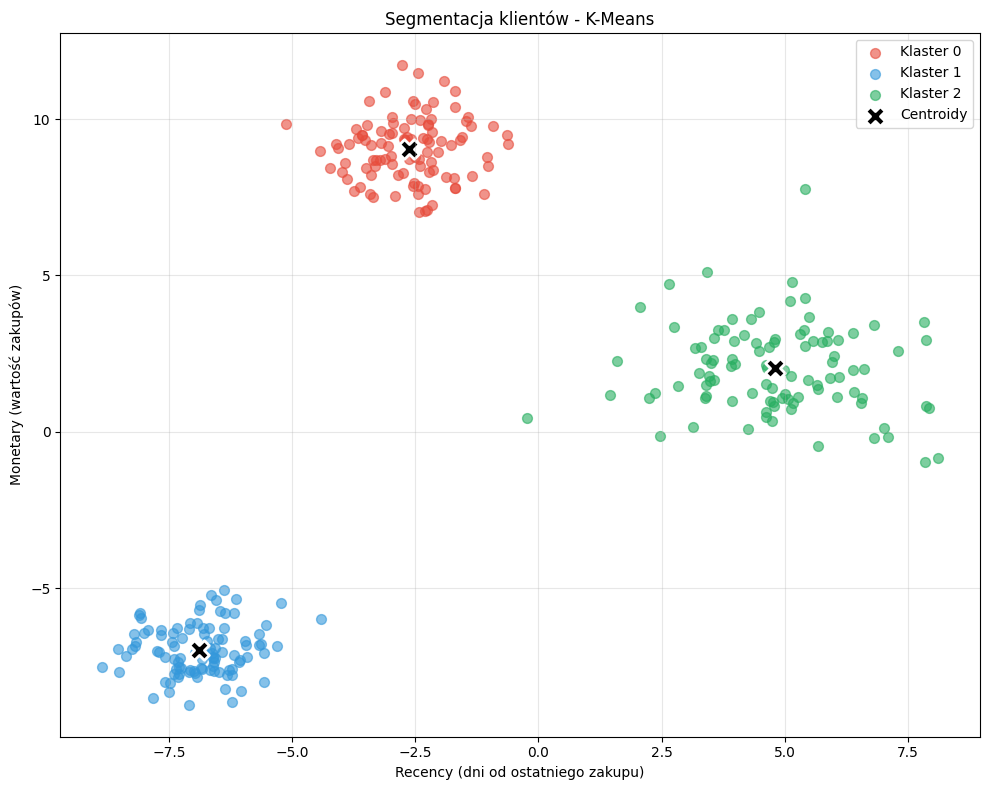

In [ ]:
#zadanie 5
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples
# Generowanie syntetycznych danych klientów
np.random.seed(42)
X, y_true = make_blobs(
n_samples=300,
n_features=2,
centers=3,
cluster_std=[1.0, 1.5, 0.8],
random_state=42
)
# Nadanie nazw cechom (symulacja RFM)
df = pd.DataFrame(X, columns=['Recency', 'Monetary'])
print("="*60)
print("KLASTERYZACJA - Segmentacja klientów")
print("="*60)
print(f"\nRozmiar danych: {df.shape}")
print(f"\nStatystyki:")
print(df.describe())
# Standaryzacja
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
# Metoda łokcia (Elbow method) - wybór liczby klastrów
inertias = []
silhouettes = []
K_range = range(2, 11)
for k in K_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(X_scaled)
  inertias.append(kmeans.inertia_)
  silhouettes.append(silhouette_score(X_scaled, kmeans.labels_))
# Wizualizacja metody łokcia
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_xlabel('Liczba klastrów (k)')
axes[0].set_ylabel('Inertia (within-cluster sum of squares)')
axes[0].set_title('Metoda łokcia (Elbow Method)')
axes[0].grid(True, alpha=0.3)
axes[1].plot(K_range, silhouettes, 'go-', linewidth=2, markersize=8)
axes[1].set_xlabel('Liczba klastrów (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score vs liczba klastrów')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
# Finalna klasteryzacja z k=3
k_optimal = 3
kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
df['Cluster'] = clusters
print(f"\nOptymalna liczba klastrów: {k_optimal}")
print(f"Silhouette Score: {silhouette_score(X_scaled, clusters):.3f}")
# Statystyki per klaster
print(f"\nStatystyki per klaster:")
cluster_stats = df.groupby('Cluster').agg({
'Recency': ['mean', 'std', 'count'],
'Monetary': ['mean', 'std']
}).round(2)
print(cluster_stats)
# Wizualizacja klastrów
fig, ax = plt.subplots(figsize=(10, 8))
colors = ['#e74c3c', '#3498db', '#27ae60', '#f39c12']
for i in range(k_optimal):
  mask = clusters == i
  ax.scatter(df.loc[mask, 'Recency'], df.loc[mask, 'Monetary'],
  c=colors[i], label=f'Klaster {i}', alpha=0.6, s=50)
# Centroidy
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
ax.scatter(centroids[:, 0], centroids[:, 1], c='black', marker='X',
s=200, edgecolors='white', linewidths=2, label='Centroidy')
ax.set_xlabel('Recency (dni od ostatniego zakupu)')
ax.set_ylabel('Monetary (wartość zakupów)')
ax.set_title('Segmentacja klientów - K-Means')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


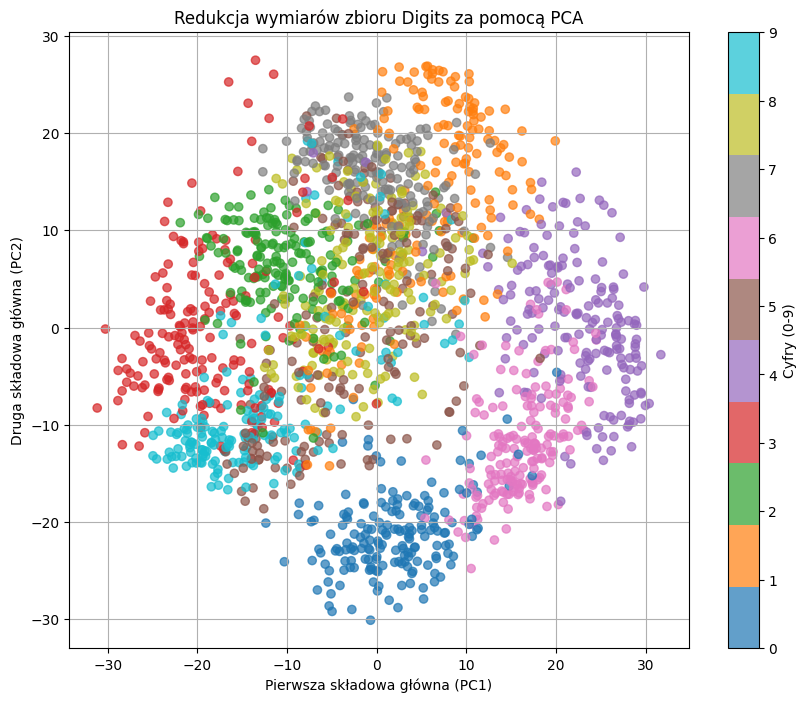

PC1: 14.89%
PC2: 13.62%
Łącznie: 28.51%


In [ ]:
#Zadanie 6 – PCA na Digits
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA

digits = load_digits()
X = digits.data
y = digits.target

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="tab10", alpha=0.7)
plt.colorbar(scatter, label="Cyfry (0-9)")
plt.xlabel("Pierwsza składowa główna (PC1)")
plt.ylabel("Druga składowa główna (PC2)")
plt.title("Redukcja wymiarów zbioru Digits za pomocą PCA")
plt.grid(True)
plt.show()

print(f"PC1: {pca.explained_variance_ratio_[0] * 100:.2f}%")
print(f"PC2: {pca.explained_variance_ratio_[1] * 100:.2f}%")
print(f"Łącznie: {pca.explained_variance_ratio_.sum() * 100:.2f}%")

WALIDACJA KRZYŻOWA (Cross-Validation)

Random Forest:
 Scores per fold: [0.96666667 0.96666667 0.93333333 0.96666667 0.9       ]
 Mean: 0.9467
 Std: 0.0267
 95% CI: [0.8944, 0.9989]


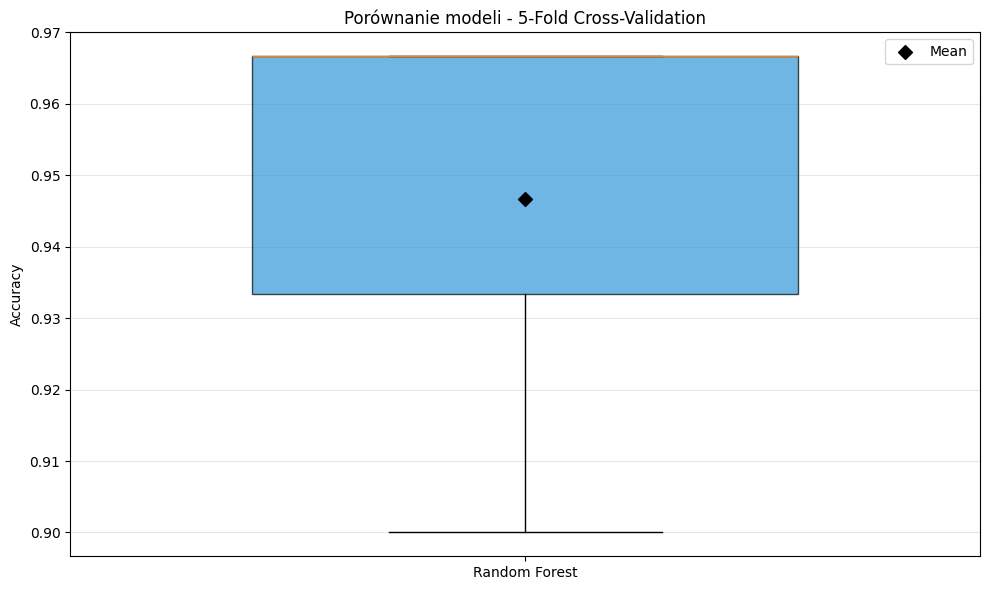

In [5]:
#zadanie 7
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import cross_val_score, KFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
# Wczytanie danych
iris = load_iris()
X, y = iris.data, iris.target
print("="*60)
print("WALIDACJA KRZYŻOWA (Cross-Validation)")
print("="*60)
# Różne modele do porównania
models = {
'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}
# 5-fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}
for name, model in models.items():
  scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')
  results[name] = scores
  print(f"\n{name}:")
  print(f" Scores per fold: {scores}")
  print(f" Mean: {scores.mean():.4f}")
  print(f" Std: {scores.std():.4f}")
  print(f" 95% CI: [{scores.mean() - 1.96*scores.std():.4f}, "
  f"{scores.mean() + 1.96*scores.std():.4f}]")
# Wizualizacja porównania
fig, ax = plt.subplots(figsize=(10, 6))
positions = np.arange(len(models))
bp = ax.boxplot([results[name] for name in models.keys()],
positions=positions, widths=0.6, patch_artist=True)
colors = ['#3498db', '#e74c3c', '#27ae60']
for patch, color in zip(bp['boxes'], colors):
  patch.set_facecolor(color)
  patch.set_alpha(0.7)
ax.set_xticks(positions)
ax.set_xticklabels(models.keys())
ax.set_ylabel('Accuracy')
ax.set_title('Porównanie modeli - 5-Fold Cross-Validation')
ax.grid(True, alpha=0.3, axis='y')
# Dodaj średnie jako punkty
means = [results[name].mean() for name in models.keys()]
ax.scatter(positions, means, c='black', marker='D', s=50, zorder=3, label='Mean')
ax.legend()
plt.tight_layout()
plt.show()



Random Forest:
 R² (train): 0.9905
 R² (test): 0.8878
 RMSE: 0.2558 ($100k)
 MAE: 0.0975 ($100k)


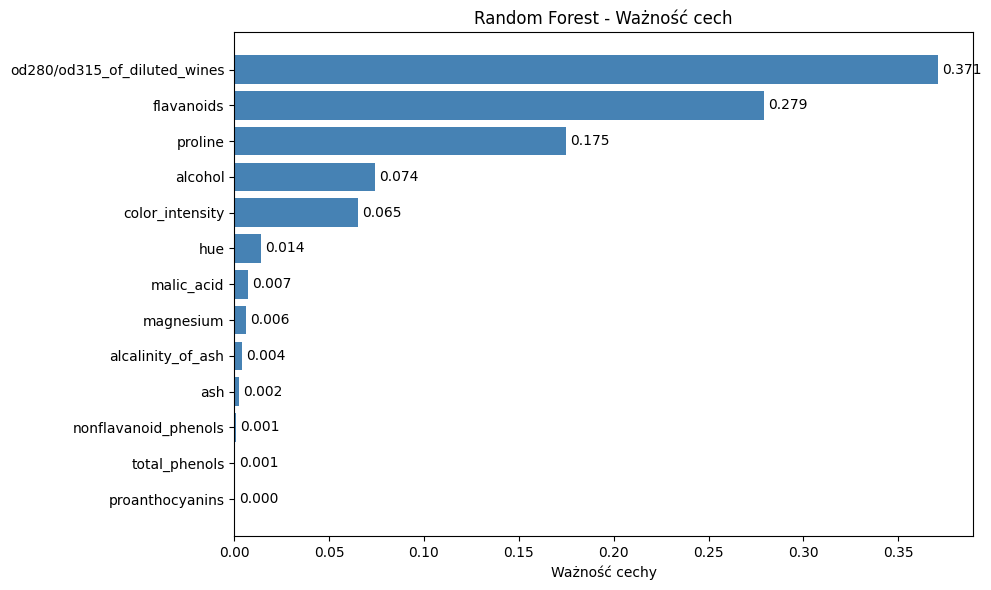

In [20]:
#zadanie 8
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Wczytanie danych
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target
# Podział i preprocessing
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
# Trening i porównanie modeli
models = {
'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
}
results = {}
for name, model in models.items():
  # Trening
  model.fit(X_train_scaled, y_train)
  # Predykcja
  y_pred_train = model.predict(X_train_scaled)
  y_pred_test = model.predict(X_test_scaled)
  # Metryki
  mse = mean_squared_error(y_test, y_pred_test)
  rmse = np.sqrt(mse)
  mae = mean_absolute_error(y_test, y_pred_test)
  r2 = r2_score(y_test, y_pred_test)
  r2_train = r2_score(y_train, y_pred_train)
  results[name] = {
  'y_pred': y_pred_test,
  'rmse': rmse,
  'mae': mae,
  'r2': r2,
  'r2_train': r2_train
  }
  print(f"\n{name}:")
  print(f" R² (train): {r2_train:.4f}")
  print(f" R² (test): {r2:.4f}")
  print(f" RMSE: {rmse:.4f} ($100k)")
  print(f" MAE: {mae:.4f} ($100k)")
# Feature importance (dla Random Forest)
rf_model = models['Random Forest']
importance = pd.DataFrame({
'feature': wine.feature_names,
'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
bars=ax.barh(importance['feature'], importance['importance'], color='steelblue')
ax.set_xlabel('Ważność cechy')
ax.set_title('Random Forest - Ważność cech')
ax.bar_label(bars, fmt='%.3f', padding=3)
plt.tight_layout()
plt.show()

KLASYFIKACJA BINARNA - Wykrywanie oszustw

Rozmiar danych: (569, 30)
Rozkład klas:
 Klasa 0 (malignant): 212 (37.3%)
 Klasa 1 (benign): 357 (62.7%)

Logistic Regression
ROC-AUC: 0.9954

Confusion Matrix:
 Predicted
 malignant benign
Actual malignant   41    1
 benign    1   71

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


Random Forest
ROC-AUC: 0.9939

Confusion Matrix:
 Predicted
 malignant benign
Actual malignant   39    3
 benign    2   70

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   ma

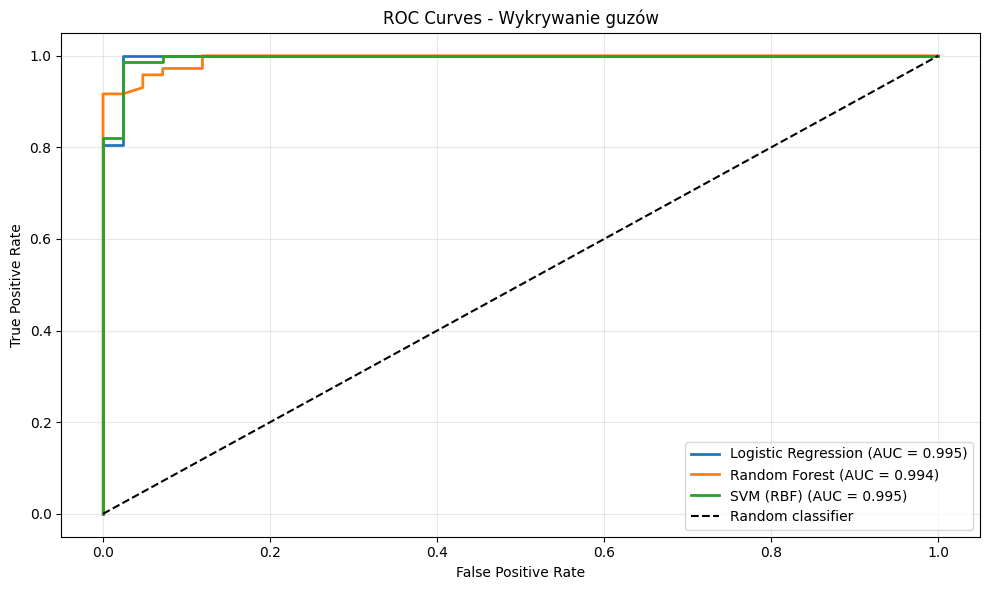

In [33]:
#zadanie 10
import numpy as np
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, roc_curve)
import matplotlib.pyplot as plt
from sklearn.svm import SVC

breast = load_breast_cancer()
X, y = breast.data, breast.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("="*60)
print("KLASYFIKACJA BINARNA - Wykrywanie oszustw")
print("="*60)
print(f"\nRozmiar danych: {X.shape}")
print(f"Rozkład klas:")
print(f" Klasa 0 (malignant): {(y == 0).sum()} ({(y == 0).mean()*100:.1f}%)")
print(f" Klasa 1 (benign): {(y == 1).sum()} ({(y == 1).mean()*100:.1f}%)")

# Podział i preprocessing

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
# Trening dwóch modeli
models = {
'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
'SVM (RBF)': SVC(    kernel='rbf',gamma='scale',probability=True,random_state=42)
}
results = {}
for name, model in models.items():
  # Trening
  model.fit(X_train_scaled, y_train)
  # Predykcje
  y_pred = model.predict(X_test_scaled)
  y_proba = model.predict_proba(X_test_scaled)[:, 1]
  # Metryki
  roc_auc = roc_auc_score(y_test, y_proba)
  cm = confusion_matrix(y_test, y_pred)
  results[name] = {
  'y_pred': y_pred,
  'y_proba': y_proba,
  'roc_auc': roc_auc,
  'cm': cm
  }
  print(f"\n{'='*40}")
  print(f"{name}")
  print(f"{'='*40}")
  print(f"ROC-AUC: {roc_auc:.4f}")
  print(f"\nConfusion Matrix:")
  print(f" Predicted")
  print(f" malignant benign")
  print(f"Actual malignant {cm[0,0]:4d} {cm[0,1]:4d}")
  print(f" benign {cm[1,0]:4d} {cm[1,1]:4d}")
  print(f"\nClassification Report:")
  print(classification_report(y_test, y_pred, target_names=['malignant', 'benign']))
# Wizualizacja ROC Curves
fig, ax = plt.subplots(figsize=(10, 6))
for name, res in results.items():
  fpr, tpr, _ = roc_curve(y_test, res['y_proba'])
  ax.plot(fpr, tpr, label=f"{name} (AUC = {res['roc_auc']:.3f})", linewidth=2)
ax.plot([0, 1], [0, 1], 'k--', label='Random classifier')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves - Wykrywanie guzów')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


WYNIKI DLA WSZYSTKICH KOMBINACJI
 n_estimators max_depth accuracy training_time
           50         5   0.9775     0.18055 s
           50        10   0.9775     0.21067 s
           50      None   0.9775     0.25129 s
          100         5   0.9775     0.35813 s
          100      None   0.9775     0.56569 s
          100        10   0.9775     0.61625 s
          200         5   0.9775     0.69906 s
          200      None   0.9775     0.99685 s
          200        10   0.9775     1.13754 s
           50         3   0.9663     0.17952 s
          200         3   0.9663     0.71560 s
          100         3   0.9663     0.72280 s
           10         5   0.9551     0.04559 s
           10      None   0.9551     0.07496 s
           10        10   0.9551     0.08007 s
           10         3   0.9438     0.04946 s


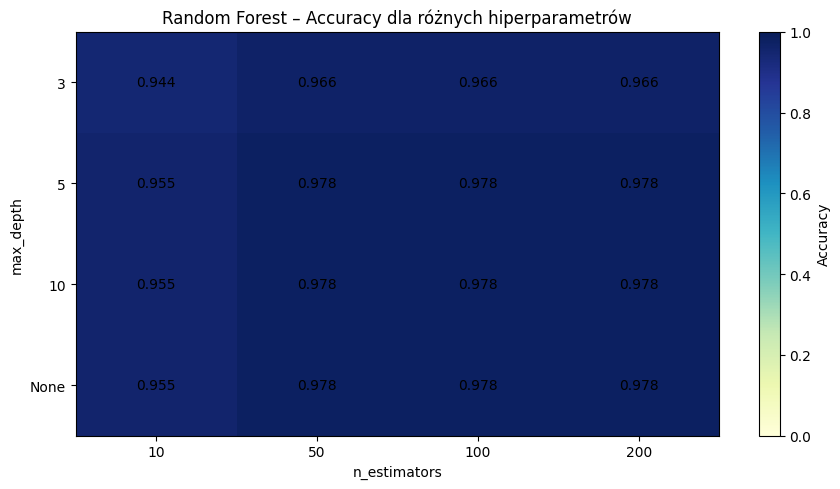

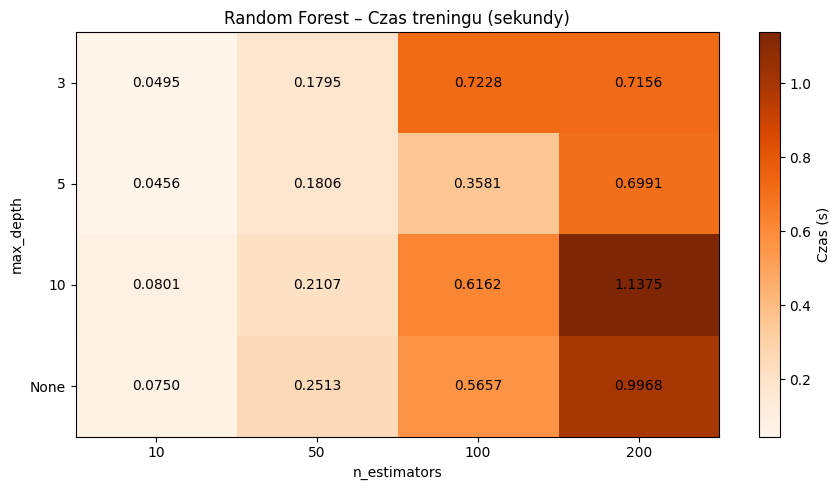


REKOMENDOWANE HIPERPARAMETRY
n_estimators: 50
max_depth: 5
Accuracy: 0.9775
Czas treningu: 0.18055 s


In [42]:
# Zadanie 16 – Analiza wrażliwości na hiperparametry
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

wine = load_wine()
X = wine.data
y = wine.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.5, #przy 0.2 accuracy wszędzie będzie 1 więc zmieniłem i są różne wyniki :)
    random_state=42,
    stratify=y
)

n_estimators_values = [10, 50, 100, 200]
max_depth_values = [3, 5, 10, None]

results = []

for depth in max_depth_values:
  for n in n_estimators_values:

    model = RandomForestClassifier(
        n_estimators=n,
        max_depth=depth,
        random_state=42,
        n_jobs=-1
    )

    start = time.perf_counter()
    model.fit(X_train, y_train)
    training_time = time.perf_counter() - start

    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        'n_estimators': n,
        'max_depth': str(depth),
        'accuracy': accuracy,
        'training_time': training_time
    })

results_df = pd.DataFrame(results)

print("WYNIKI DLA WSZYSTKICH KOMBINACJI")
print(
    results_df.sort_values(
        ['accuracy', 'training_time'],ascending=[False, True]
    ).to_string(
        index=False,
        formatters={'accuracy': '{:.4f}'.format,'training_time': '{:.5f} s'.format}
    )
)

heatmap_data = results_df.pivot(
    index='max_depth',
    columns='n_estimators',
    values='accuracy'
)

heatmap_data = heatmap_data.reindex(['3', '5', '10', 'None'])

fig, ax = plt.subplots(figsize=(9, 5))

im = ax.imshow(
    heatmap_data.values,
    cmap='YlGnBu',
    aspect='auto',
    vmin=0,
    vmax=1
)

ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns)
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)

ax.set_xlabel('n_estimators')
ax.set_ylabel('max_depth')
ax.set_title('Random Forest – Accuracy dla różnych hiperparametrów')

for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        value = heatmap_data.iloc[i, j]
        ax.text(
            j, i, f'{value:.3f}',
            ha='center',
            va='center',
            color='black'
        )

fig.colorbar(im, ax=ax, label='Accuracy')
plt.tight_layout()
plt.show()

time_data = results_df.pivot(
    index='max_depth',
    columns='n_estimators',
    values='training_time'
).reindex(['3', '5', '10', 'None'])

fig, ax = plt.subplots(figsize=(9, 5))

im = ax.imshow(time_data.values, cmap='Oranges', aspect='auto')

ax.set_xticks(range(len(time_data.columns)))
ax.set_xticklabels(time_data.columns)
ax.set_yticks(range(len(time_data.index)))
ax.set_yticklabels(time_data.index)

ax.set_xlabel('n_estimators')
ax.set_ylabel('max_depth')
ax.set_title('Random Forest – Czas treningu (sekundy)')

for i in range(time_data.shape[0]):
    for j in range(time_data.shape[1]):
        ax.text(
            j, i, f'{time_data.iloc[i, j]:.4f}',
            ha='center',
            va='center',
            color='black'
        )

fig.colorbar(im, ax=ax, label='Czas (s)')
plt.tight_layout()
plt.show()

# 8. Rekomendacja – najwyższe accuracy,
# a przy remisie najkrótszy czas treningu
best = results_df.sort_values(
    ['accuracy', 'training_time'],
    ascending=[False, True]
).iloc[0]

print("\nREKOMENDOWANE HIPERPARAMETRY")
print(f"n_estimators: {best['n_estimators']}")
print(f"max_depth: {best['max_depth']}")
print(f"Accuracy: {best['accuracy']:.4f}")
print(f"Czas treningu: {best['training_time']:.5f} s")

